In [47]:
import pandas as pd
from sklearn.svm import SVC
import numpy as np

In [48]:
df = pd.read_csv('./dataset/nepal_remittance_dataset.csv')

In [49]:
df.head()

,household_id,province,district,urban_rural,ecological_belt,household_size,num_dependents,head_age,head_gender,head_education,...,migration_duration_years,migrant_education_level,land_ownership_area,total_annual_income,house_ownership,num_rooms,loan_status,annual_remittance_npr,remittance_dependency_class,num_rooms_dup1
0,HH03961,Sudurpashchim,Kanchanpur,urban,mountain,7.0,0.0,29.0,male,secondary,...,7.0,secondary,0.06,317343.0,owned,7.0,none,142939.0,Medium,7.0
1,HH04385,Bagmati,Lalitpur,rural,mountain,5.0,2.0,69.0,male,primary,...,3.0,secondary,0.29,193616.0,rented,40.0,active,108073.0,Medium,40.0
2,HH01797,Sudurpashchim,Kailali,urban,mountain,2.0,0.0,55.0,female,secondary,...,15.0,secondary,0.41,285413.0,owned,2.0,none,263669.0,Medium,2.0
3,HH02786,Koshi,Morang,urban,hill,2.0,0.0,70.0,male,primary,...,8.0,none,0.26,222161.0,rented,6.0,active,104333.0,Medium,6.0
4,HH01676,Sudurpashchim,Baitadi,rural,mountain,4.0,0.0,77.0,female,masters,...,15.0,primary,0.40,228461.0,owned,7.0,active,65588.0,Low,7.0


In [52]:
df['migrant_education_level']

TypeError: Index(...) must be called with a collection of some kind, 'primary' was passed

In [4]:
df.loc[df["annual_remittance_npr"] < 0, "annual_remittance_npr"] = np.nan
df["annual_remittance_npr"] = df["annual_remittance_npr"].fillna(
    df["annual_remittance_npr"].median()
)

In [5]:
df.loc[df["total_annual_income"] < 0, "total_annual_income"] = np.nan
df["total_annual_income"] = df["total_annual_income"].fillna(
    df["total_annual_income"].median()
)


# df = df[
#     (df["num_dependents"] >= 1)
# ]

In [6]:
mean_dependents = df.loc[
    (df["num_dependents"] >= 1) &
    (df["num_dependents"] <= 20),
    "num_dependents"
].mean()

df.loc[
    (df["num_dependents"] < 1) |
    (df["num_dependents"] > 20),
    "num_dependents"
] = mean_dependents

In [7]:
(df["total_annual_income"] < 0).sum()

np.int64(0)

In [8]:
df.describe()

,household_size,num_dependents,head_age,num_migrant_members,migration_duration_years,land_ownership_area,total_annual_income,num_rooms,annual_remittance_npr,num_rooms_dup1
count,4998.000000,4996.000000,5004.000000,4991.000000,4988.000000,5004.000000,5.050000e+03,4997.000000,5.050000e+03,4996.000000
mean,6.819823,2.986705,62.799694,0.959728,668.161403,0.575832,2.615691e+05,5.261143,1.313035e+05,5.232572
std,19.598911,1.650936,153.806871,0.895200,15690.612633,1.701843,5.715242e+05,13.034055,3.621481e+05,12.889636
min,-29.979864,1.000000,-283.943820,0.000000,-59.627359,-6.746337,3.000000e+04,-24.949118,0.000000e+00,-24.949118
25%,4.000000,2.000000,36.000000,0.000000,0.000000,0.150000,1.717610e+05,3.000000,0.000000e+00,3.000000
50%,6.000000,2.986705,51.000000,1.000000,4.000000,0.350000,2.184780e+05,5.000000,8.913000e+04,5.000000
75%,8.000000,4.000000,66.000000,1.000000,10.000000,0.692500,2.683380e+05,7.000000,1.650632e+05,7.000000
max,450.000000,10.000000,4000.000000,3.000000,500000.000000,61.000000,1.449960e+07,400.000000,1.041315e+07,400.000000


In [9]:
df['head_age'].value_counts()

head_age
22.0      117
35.0      109
64.0       98
26.0       95
60.0       95
         ... 
1150.0      1
920.0       1
1540.0      1
300.0       1
1040.0      1
Name: count, Length: 111, dtype: int64

In [10]:
df.loc[(df["head_age"] < 18) | (df["head_age"] > 100), "head_age"] = np.nan
df["head_age"] = df["head_age"].fillna(df["head_age"].mean())

In [11]:
df.loc[(df["household_size"] < 0), "household_size"] = np.nan
df["household_size"] = df["household_size"].fillna(df["head_age"].mean())

In [12]:
df.loc[(df["land_ownership_area"] < 0), "land_ownership_area"] = np.nan
df["land_ownership_area"] = df["land_ownership_area"].fillna(df["land_ownership_area"].mean())


In [13]:
df = df[
    (df["migration_duration_years"] >= 0) &
    (df["migration_duration_years"] <= 15)
]

In [14]:
df['remittance_dependency_class'].value_counts()

remittance_dependency_class
Medium           2336
No_Remittance    1729
Low               468
High              402
Name: count, dtype: int64

In [15]:
df.isnull().sum()

household_id                    0
province                       42
district                       47
urban_rural                    54
ecological_belt                49
household_size                  0
num_dependents                 54
head_age                        0
head_gender                    48
head_education                 38
num_migrant_members            59
migrant_destination            41
migration_duration_years        0
migrant_education_level        40
land_ownership_area             0
total_annual_income             0
house_ownership                51
num_rooms                      49
loan_status                    57
annual_remittance_npr           0
remittance_dependency_class     0
num_rooms_dup1                 53
dtype: int64

In [16]:
df["household_size"] = df["household_size"].fillna(df["household_size"].mean())
# df["total_annual_income"] = df["total_annual_income"].fillna(df["total_annual_income"].mean())
# df["head_age"] = df["head_age"].fillna(df["head_age"].mean())
df["num_dependents"] = df["num_dependents"].fillna(df["num_dependents"].mean())
df["num_migrant_members"] = df["num_migrant_members"].fillna(df["num_migrant_members"].mean())
df["migration_duration_years"] = df["migration_duration_years"].fillna(df["migration_duration_years"].mean())
# df["num_rooms"] = df["num_rooms"].fillna(df["num_rooms"].mean())
df["land_ownership_area"] = df["land_ownership_area"].fillna(df["land_ownership_area"].mean())

In [17]:
# import seaborn as sns
# import matplotlib.pyplot as plt

# sns.heatmap(df.isnull(), cbar=False)

# plt.show()

In [18]:
df.isnull().sum()

household_id                    0
province                       42
district                       47
urban_rural                    54
ecological_belt                49
household_size                  0
num_dependents                  0
head_age                        0
head_gender                    48
head_education                 38
num_migrant_members             0
migrant_destination            41
migration_duration_years        0
migrant_education_level        40
land_ownership_area             0
total_annual_income             0
house_ownership                51
num_rooms                      49
loan_status                    57
annual_remittance_npr           0
remittance_dependency_class     0
num_rooms_dup1                 53
dtype: int64

In [19]:
# df = df.dropna(subset=["urban_rural"])
df = df.dropna()

In [20]:
# df = df.fillna(None
df.shape

(4394, 22)

In [21]:

df.info()

<class 'pandas.DataFrame'>
Index: 4394 entries, 0 to 5049
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   household_id                 4394 non-null   str    
 1   province                     4394 non-null   str    
 2   district                     4394 non-null   str    
 3   urban_rural                  4394 non-null   str    
 4   ecological_belt              4394 non-null   str    
 5   household_size               4394 non-null   float64
 6   num_dependents               4394 non-null   float64
 7   head_age                     4394 non-null   float64
 8   head_gender                  4394 non-null   str    
 9   head_education               4394 non-null   str    
 10  num_migrant_members          4394 non-null   float64
 11  migrant_destination          4394 non-null   str    
 12  migration_duration_years     4394 non-null   float64
 13  migrant_education_level      4394 

In [22]:
df.isnull().sum()
df['migrant_education_level'].value_counts()


migrant_education_level
none         1946
secondary    1193
primary       817
bachelor      438
Name: count, dtype: int64

In [23]:
df['head_education'] = df['head_education'].map({'none': 0,'primary':1,'secondary':2,'higher_secondary':3,'bachelor':4,'masters':5})
df['loan_status'] = df['loan_status'].map({'none': 0,'active':1})
df['migrant_education_level'] = df['migrant_education_level'].map({'none': 0,'primary':1,'secondary':2,'higher_secondary':3,'bachelor':4})

In [24]:
X = df.drop(columns=[
    "household_id",
    "head_gender",
    # "num_rooms_dup1",
])

In [25]:
df.shape

(4394, 22)

In [26]:
df['migrant_destination'].value_counts()

migrant_destination
none        1519
gulf        1147
india        855
malaysia     574
other        299
Name: count, dtype: int64

In [27]:
del df['num_rooms_dup1']
del df['num_rooms']

In [28]:
y = X['remittance_dependency_class']

In [29]:
del X['remittance_dependency_class']
# del X['annual_remittance_npr']
# del X["total_annual_income"]

In [30]:
X

,province,district,urban_rural,ecological_belt,household_size,num_dependents,head_age,head_education,num_migrant_members,migrant_destination,migration_duration_years,migrant_education_level,land_ownership_area,total_annual_income,house_ownership,num_rooms,loan_status,annual_remittance_npr,num_rooms_dup1
0,Sudurpashchim,Kanchanpur,urban,mountain,7.0,2.986705,29.0,2,1.0,gulf,7.0,2,0.06,317343.0,owned,7.0,0,142939.0,7.0
1,Bagmati,Lalitpur,rural,mountain,5.0,2.000000,69.0,1,1.0,gulf,3.0,2,0.29,193616.0,rented,40.0,1,108073.0,40.0
2,Sudurpashchim,Kailali,urban,mountain,2.0,2.986705,55.0,2,3.0,other,15.0,2,0.41,285413.0,owned,2.0,0,263669.0,2.0
3,Koshi,Morang,urban,hill,2.0,2.986705,70.0,1,1.0,malaysia,8.0,0,0.26,222161.0,rented,6.0,1,104333.0,6.0
4,Sudurpashchim,Baitadi,rural,mountain,4.0,2.986705,77.0,5,1.0,india,15.0,1,0.40,228461.0,owned,7.0,1,65588.0,7.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5045,Gandaki,Kaski,urban,hill,6.0,2.986705,78.0,3,1.0,malaysia,8.0,1,0.22,274237.0,owned,5.0,1,88306.0,5.0
5046,Koshi,Ilam,urban,hill,6.0,1.000000,41.0,1,1.0,malaysia,14.0,1,0.09,225467.0,owned,8.0,0,114183.0,8.0
5047,Lumbini,Rupandehi,rural,terai,8.0,7.000000,71.0,0,1.0,gulf,2.0,2,0.93,178838.0,owned,7.0,0,135008.0,7.0
5048,Gandaki,Baglung,urban,hill,7.0,3.000000,36.0,0,1.0,gulf,6.0,2,1.26,278225.0,owned,5.0,0,89130.0,5.0


In [31]:
df['head_education'].value_counts()

head_education
1    1116
2    1105
0     841
3     678
4     435
5     219
Name: count, dtype: int64

In [32]:
columns = pd.get_dummies(df[['migrant_destination',"province","district","urban_rural","ecological_belt"]]).astype(int)

In [33]:
columns2 = pd.get_dummies(df['house_ownership']).astype(int)

In [34]:
del X['migrant_destination']
del X['house_ownership']
del X['province']
del X['urban_rural']
del X['ecological_belt']
del X['district']

In [35]:
X = pd.concat([X,columns,columns2],axis=1)

In [36]:
# X["loan_status"] = X["loan_status"].str.replace({
#     'none':0,"active":1
# })

In [37]:
X.info()

<class 'pandas.DataFrame'>
Index: 4394 entries, 0 to 5049
Data columns (total 60 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   household_size                4394 non-null   float64
 1   num_dependents                4394 non-null   float64
 2   head_age                      4394 non-null   float64
 3   head_education                4394 non-null   int64  
 4   num_migrant_members           4394 non-null   float64
 5   migration_duration_years      4394 non-null   float64
 6   migrant_education_level       4394 non-null   int64  
 7   land_ownership_area           4394 non-null   float64
 8   total_annual_income           4394 non-null   float64
 9   num_rooms                     4394 non-null   float64
 10  loan_status                   4394 non-null   int64  
 11  annual_remittance_npr         4394 non-null   float64
 12  num_rooms_dup1                4394 non-null   float64
 13  migrant_destination

In [38]:
df['loan_status'].value_counts()

loan_status
0    2811
1    1583
Name: count, dtype: int64

In [39]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix,ConfusionMatrixDisplay
import seaborn as sns
import matplotlib.pyplot as plt

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

In [41]:
X_test.shape

(879, 60)

In [42]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [43]:
model = SVC(kernel='linear',C=1)
model.fit(X_train_scaled, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [44]:
y_pred = model.predict(X_test_scaled)

In [45]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.926052332195677
               precision    recall  f1-score   support

         High       0.83      0.72      0.77        68
          Low       0.78      0.76      0.77        79
       Medium       0.91      0.94      0.92       419
No_Remittance       1.00      1.00      1.00       313

     accuracy                           0.93       879
    macro avg       0.88      0.85      0.87       879
 weighted avg       0.92      0.93      0.93       879



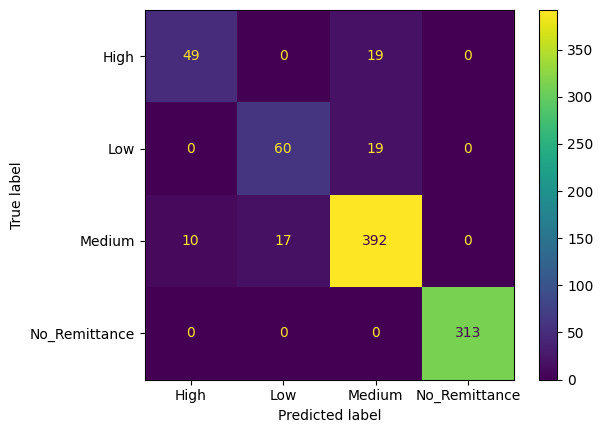

In [46]:
cm = confusion_matrix(y_test,y_pred,labels=model.classes_)
ConfusionMatrixDisplay(confusion_matrix =cm,display_labels = model.classes_).plot()

In [166]:
df = df[
    (df["migration_duration_years"] >= 0) &
    (df["migration_duration_years"] <= 15)
]

In [44]:
df['migration_duration_years'].value_counts()

migration_duration_years
0.0     1519
2.0      224
12.0     213
15.0     207
6.0      198
13.0     196
10.0     193
1.0      192
5.0      191
3.0      190
14.0     189
9.0      184
11.0     179
4.0      179
8.0      174
7.0      166
Name: count, dtype: int64

In [45]:
X.shape

(4394, 59)